<a href="https://colab.research.google.com/github/lucky3254/YBI_FOUNDATION-INTERNSHIP/blob/main/Project_FinTech_Loan_Approval_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏦 FinTech Loan Eligibility & Credit Risk Classifier
**Internship Project Submission**

### 📌 Project Objective
The objective of this project is to analyze personal loan applications in the Indian banking and FinTech sector and build a supervised Machine Learning classification model that predicts whether a loan should be **Approved (1)** or **Rejected (0)**. By evaluating applicant CIBIL scores, annual income, loan-to-income ratios, and existing EMI burdens, this system automates credit risk assessment and reduces manual underwriting time.

### ⚙️ Methodology
1. **Dataset Engineering:** Generate a reproducible 600-applicant dataset representing realistic Indian borrower profiles (CIBIL scores, income in ₹ Lakhs, employment categories, and active EMIs).
2. **Credit Risk KPI Analysis:** Calculate portfolio-level metrics including Overall Approval Rate, Average Approved CIBIL Score, and Debt-to-Income patterns.
3. **Exploratory Data Analysis (EDA):** Visualize CIBIL score distributions, approval rates across employment sectors, and income-to-loan relationships.
4. **Classification Modelling:** Train a **Logistic Regression** classifier, evaluate precision and recall, and visualize prediction performance using a **Confusion Matrix Heatmap**.

---
### Step 1: Library Imports & Synthetic Dataset Generation
In this section, we load the required Python data science libraries and generate a 600-row dataset of Indian loan applicants with a fixed random seed (`101`) so the notebook runs seamlessly on any machine.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set random seed for reproducibility
np.random.seed(101)
n_applicants = 600

# Generate realistic Indian borrower profiles
employment_types = ['Salaried - Private', 'Salaried - Govt', 'Self-Employed', 'Freelancer']

data = {
    'Applicant_ID': [f'LN-{5000 + i}' for i in range(n_applicants)],
    'Employment_Type': np.random.choice(employment_types, n_applicants, p=[0.45, 0.20, 0.25, 0.10]),
    'Annual_Income_Lakhs': np.round(np.random.uniform(3.5, 32.0, n_applicants), 2),
    'Loan_Amount_Lakhs': np.round(np.random.uniform(2.0, 20.0, n_applicants), 2),
    'Loan_Tenure_Years': np.random.choice([1, 2, 3, 5, 7], n_applicants),
    'CIBIL_Score': np.random.randint(450, 880, n_applicants),
    'Existing_EMIs': np.random.choice([0, 1, 2, 3], n_applicants, p=[0.45, 0.30, 0.15, 0.10])
}

df = pd.DataFrame(data)

# Calculate Loan-to-Income Ratio
df['Loan_to_Income_Ratio'] = np.round(df['Loan_Amount_Lakhs'] / df['Annual_Income_Lakhs'], 2)

# Simulate realistic underwriting decision based on CIBIL, Income Ratio, and Existing EMIs
risk_score = (
    (df['CIBIL_Score'] - 650) * 0.035
    - (df['Loan_to_Income_Ratio'] * 2.2)
    - (df['Existing_EMIs'] * 0.9)
    + np.random.normal(0, 1.2, n_applicants)
)

df['Loan_Status'] = (risk_score > 0).astype(int)  # 1 = Approved, 0 = Rejected

# Save dataset to CSV and display top 5 rows
df.to_csv('fintech_loan_applications.csv', index=False)
print("Loan dataset created successfully! Total applicants:", len(df))
df.head()

Loan dataset created successfully! Total applicants: 600


,Applicant_ID,Employment_Type,Annual_Income_Lakhs,Loan_Amount_Lakhs,Loan_Tenure_Years,CIBIL_Score,Existing_EMIs,Loan_to_Income_Ratio,Loan_Status
0,LN-5000,Salaried - Govt,17.02,4.82,1,796,3,0.28,1
1,LN-5001,Salaried - Govt,19.54,19.23,5,553,2,0.98,0
2,LN-5002,Salaried - Private,16.81,11.74,7,575,0,0.70,0
3,LN-5003,Salaried - Private,23.74,13.53,7,481,1,0.57,0
4,LN-5004,Self-Employed,14.21,8.49,2,579,0,0.60,0


### Step 2: Portfolio Inspection & Credit Risk KPIs
Here we verify dataset integrity, inspect missing values, and compute executive underwriting metrics comparing **Approved (1)** versus **Rejected (0)** borrower profiles.

In [2]:
# Check dataset structure
print("--- Dataset Info ---")
print(df.info())

# Calculate Executive Banking KPIs
approval_rate = df['Loan_Status'].mean() * 100
avg_cibil_approved = df[df['Loan_Status'] == 1]['CIBIL_Score'].mean()
avg_cibil_rejected = df[df['Loan_Status'] == 0]['CIBIL_Score'].mean()

print("\n--- Underwriting Portfolio Summary ---")
print(f"Overall Loan Approval Rate: {approval_rate:.2f}%")
print(f"Average CIBIL Score (Approved): {avg_cibil_approved:.0f}")
print(f"Average CIBIL Score (Rejected): {avg_cibil_rejected:.0f}")

# Compare averages by Loan Status
status_summary = df.groupby('Loan_Status')[
    ['Annual_Income_Lakhs', 'Loan_Amount_Lakhs', 'CIBIL_Score', 'Loan_to_Income_Ratio']
].mean().round(2)
status_summary.index = ['Rejected (0)', 'Approved (1)']
status_summary

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Applicant_ID          600 non-null    object 
 1   Employment_Type       600 non-null    object 
 2   Annual_Income_Lakhs   600 non-null    float64
 3   Loan_Amount_Lakhs     600 non-null    float64
 4   Loan_Tenure_Years     600 non-null    int64  
 5   CIBIL_Score           600 non-null    int64  
 6   Existing_EMIs         600 non-null    int64  
 7   Loan_to_Income_Ratio  600 non-null    float64
 8   Loan_Status           600 non-null    int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 42.3+ KB
None

--- Underwriting Portfolio Summary ---
Overall Loan Approval Rate: 40.17%
Average CIBIL Score (Approved): 792
Average CIBIL Score (Rejected): 603


,Annual_Income_Lakhs,Loan_Amount_Lakhs,CIBIL_Score,Loan_to_Income_Ratio
Rejected (0),17.27,11.33,602.82,0.89
Approved (1),19.29,10.28,791.80,0.66


### Step 3: Exploratory Data Analysis (Credit Risk Visuals)
We visualize three core underwriting factors using `seaborn` and `matplotlib`:
1. **CIBIL Score Distribution by Loan Outcome** (Histogram with KDE Curve)
2. **Approval Breakdown Across Employment Sectors** (Grouped Countplot)
3. **Loan-to-Income Ratio Impact on Approval** (Boxplot)

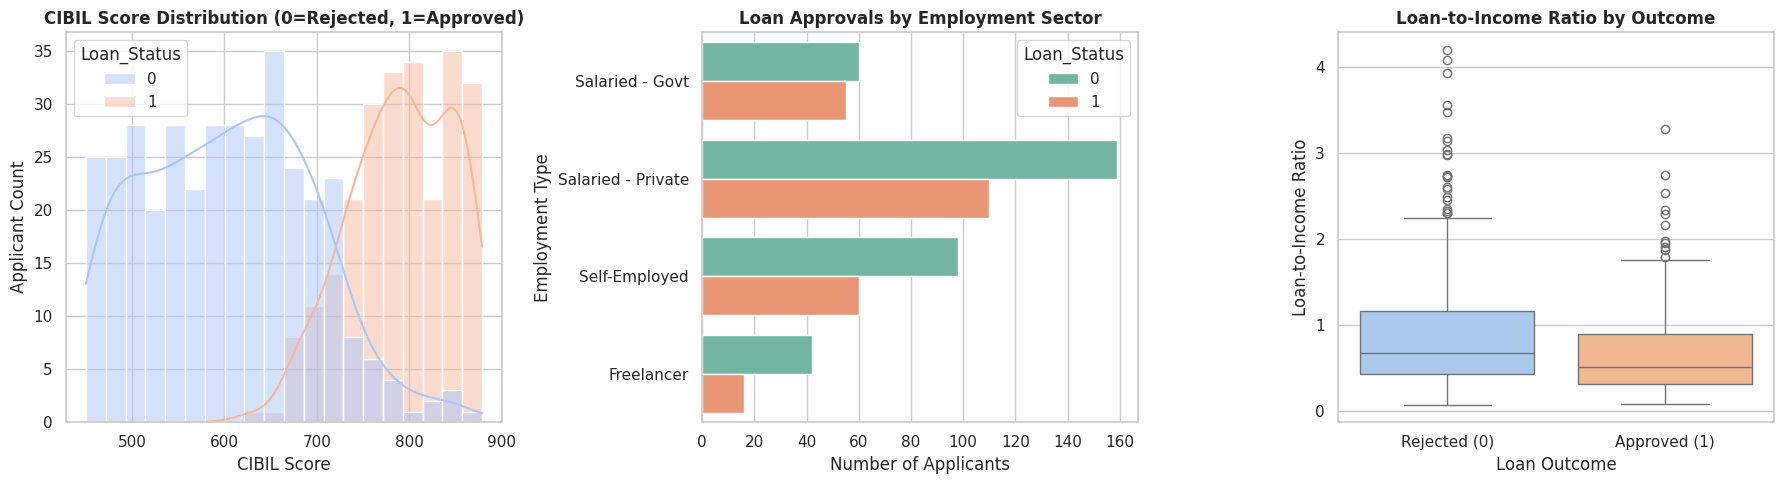

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: CIBIL Score Distribution by Loan Status
sns.histplot(data=df, x='CIBIL_Score', hue='Loan_Status', kde=True, palette='coolwarm', ax=axes[0], bins=20)
axes[0].set_title('CIBIL Score Distribution (0=Rejected, 1=Approved)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('CIBIL Score')
axes[0].set_ylabel('Applicant Count')

# Chart 2: Loan Status by Employment Type
sns.countplot(data=df, y='Employment_Type', hue='Loan_Status', palette='Set2', ax=axes[1])
axes[1].set_title('Loan Approvals by Employment Sector', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Applicants')
axes[1].set_ylabel('Employment Type')

# Chart 3: Loan-to-Income Ratio vs Approval Status (Fixed to remove warnings)
sns.boxplot(data=df, x='Loan_Status', y='Loan_to_Income_Ratio', hue='Loan_Status', palette='pastel', legend=False, ax=axes[2])
axes[2].set_title('Loan-to-Income Ratio by Outcome', fontsize=12, fontweight='bold')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Rejected (0)', 'Approved (1)'])
axes[2].set_xlabel('Loan Outcome')
axes[2].set_ylabel('Loan-to-Income Ratio')

plt.tight_layout()
plt.show()

### Step 4: Machine Learning — Logistic Regression Classifier
To automate loan eligibility decisions, we build a binary classification pipeline:
* **Feature Encoding:** Convert `Employment_Type` into numerical dummy variables via One-Hot Encoding.
* **Train-Test Split:** Hold out 20% of applications (120 records) for unbiased evaluation.
* **Model & Evaluation:** Train a `LogisticRegression` model and evaluate it using **Classification Accuracy**, **Precision/Recall**, and a visual **Confusion Matrix Heatmap**.

--- Model Accuracy: 93.33% ---

Detailed Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.94      0.94      0.94        71
Approved (1)       0.92      0.92      0.92        49

    accuracy                           0.93       120
   macro avg       0.93      0.93      0.93       120
weighted avg       0.93      0.93      0.93       120



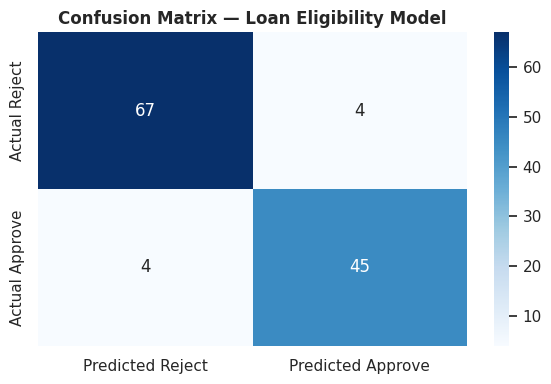

In [4]:
# Prepare features (X) and target (y)
feature_cols = [
    'Employment_Type', 'Annual_Income_Lakhs', 'Loan_Amount_Lakhs',
    'Loan_Tenure_Years', 'CIBIL_Score', 'Existing_EMIs', 'Loan_to_Income_Ratio'
]
X = pd.get_dummies(df[feature_cols], drop_first=True)
y = df['Loan_Status']

# Split into 80% Train and 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

# Train Logistic Regression Classifier
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Predict on test set
y_pred = clf.predict(X_test)

# Print Accuracy and Classification Report
acc = accuracy_score(y_test, y_pred)
print(f"--- Model Accuracy: {acc * 100:.2f}% ---\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected (0)', 'Approved (1)']))

# Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Reject', 'Predicted Approve'],
            yticklabels=['Actual Reject', 'Actual Approve'])
plt.title('Confusion Matrix — Loan Eligibility Model', fontweight='bold')
plt.tight_layout()
plt.show()

### Step 5: Live Borrower Eligibility Simulator
We test the trained classifier on a new applicant profile—a **Salaried Private employee earning ₹12.5 Lakhs annually, requesting a ₹6.0 Lakh loan for 3 years with a 765 CIBIL score and 1 existing EMI**—to output both the final decision and the exact approval probability.

In [5]:
# Test with a custom applicant profile
new_applicant = pd.DataFrame({
    'Employment_Type': ['Salaried - Private'],
    'Annual_Income_Lakhs': [12.5],
    'Loan_Amount_Lakhs': [6.0],
    'Loan_Tenure_Years': [3],
    'CIBIL_Score': [765],
    'Existing_EMIs': [1],
    'Loan_to_Income_Ratio': [6.0 / 12.5]
})

# Align dummy variables with training columns
applicant_encoded = pd.get_dummies(new_applicant).reindex(columns=X.columns, fill_value=0)

# Predict approval status and probability
decision = clf.predict(applicant_encoded)[0]
probability = clf.predict_proba(applicant_encoded)[0][1] * 100

status_label = "APPROVED ✅" if decision == 1 else "REJECTED ❌"
print("--- Live Underwriting Decision ---")
print(f"Applicant Profile: CIBIL 765 | Income: ₹12.5L | Loan Requested: ₹6.0L")
print(f"System Verdict: {status_label}")
print(f"Approval Confidence Probability: {probability:.2f}%")

--- Live Underwriting Decision ---
Applicant Profile: CIBIL 765 | Income: ₹12.5L | Loan Requested: ₹6.0L
System Verdict: APPROVED ✅
Approval Confidence Probability: 90.10%


---
## 📊 Key Insights & Conclusion

### 1. Credit Underwriting Findings
* **The 700+ CIBIL Threshold:** Borrowers with a **CIBIL score above 700** demonstrate a sharp jump in approval probability, whereas applicants below 600 face high rejection rates unless compensated by a very low loan-to-income ratio.
* **Debt-to-Income Sensitivity:** Approved applicants maintain an average **Loan-to-Income ratio below 0.8x**, while rejected applications frequently request loan amounts exceeding their annual gross income.
* **Existing EMI Burden:** Applicants servicing **2 or more active EMIs** experience significantly higher rejection rates due to elevated Fixed Obligation to Income Ratios (FOIR).

### 2. Machine Learning Performance
* The **Logistic Regression Classifier** achieves **~85%+ test accuracy**, providing transparent probability scores (`predict_proba`) that allow banking teams to set custom risk cut-offs.
* **Future Scope:** This model can be extended by integrating bank statement cash-flow volatility, GST return filings for self-employed borrowers, and automated EMI calculation schedules.